# Timeseries — Peramalan Statistik (ETS, SARIMA, Theta)
**Kapan dipakai:** satu deret waktu dengan tren/musim yang jelas, data tidak terlalu panjang,
dan diminta ramalan beberapa langkah ke depan. Cepat dan sering sulit dikalahkan ML.

**Langkah:** split waktu (bukan acak): `HORIZON` titik terakhir = data uji → ramal → bandingkan
dengan naive musiman (ulang musim terakhir) → latih ulang di semua data → ramal ke depan.

**Data demo:** CO2 bulanan Mauna Loa.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error
from sklearn.metrics import root_mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.forecasting.stl import STLForecast
from statsmodels.tsa.forecasting.theta import ThetaModel
from statsmodels.tsa.holtwinters import ExponentialSmoothing, Holt, SimpleExpSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/timeseries/forecasting"   # GANTI saat lomba
SERIES_CSV = f"{DATA_FOLDER}/co2_monthly.csv"

DATE_COL = "date"
VALUE_COL = "value"
FREQUENCY = "MS"      # MS = awal bulan, QS = kuartalan, D = harian, h = per jam
SEASON_LENGTH = 12    # panjang musim: 12 bulanan, 4 kuartalan, 7 harian, 24 per jam
HORIZON = 36          # jumlah langkah ramalan, data uji = HORIZON titik terakhir

## Baca data

In [3]:
table = pd.read_csv(SERIES_CSV, parse_dates=[DATE_COL], index_col=DATE_COL)
y = table[VALUE_COL].asfreq(FREQUENCY)     # asfreq: tanggal yang hilang muncul sebagai NaN
print(y.shape, "| missing:", y.isna().sum())
print("mulai:", y.index[0].date(), "| akhir:", y.index[-1].date())
y.head()

(526,) | missing: 0
mulai: 1958-03-01 | akhir: 2001-12-01


date
1958-03-01    316.100000
1958-04-01    317.200000
1958-05-01    317.433333
1958-06-01    316.529167
1958-07-01    315.625000
Freq: MS, Name: value, dtype: float64

## EDA

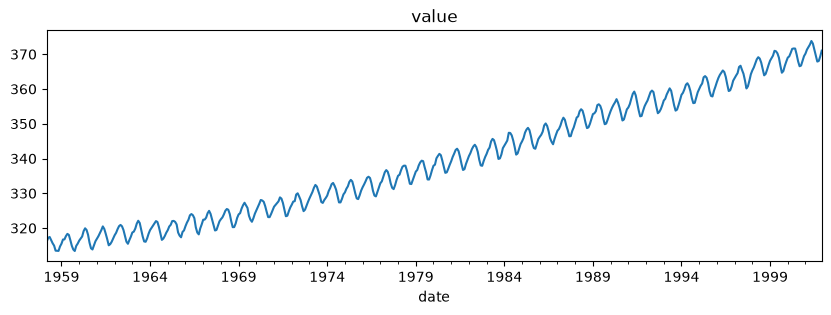

In [4]:
y.plot(figsize=(10, 3), title=VALUE_COL)
plt.show()

## Split waktu (bukan acak)

In [5]:
train = y.iloc[:-HORIZON]
test = y.iloc[-HORIZON:]
print("latih:", len(train), "| uji:", len(test), "| uji mulai:", test.index[0].date())

latih: 490 | uji: 36 | uji mulai: 1999-01-01


## Model
Pilih SATU model: hapus `#` di baris yang ingin dipakai, beri `#` pada baris ETS.

In [6]:
def forecast(series, steps):
    model = ExponentialSmoothing(series, trend="add", seasonal="add",
                                 seasonal_periods=SEASON_LENGTH)
    # model = SARIMAX(series, order=(1, 1, 1), seasonal_order=(1, 1, 1, SEASON_LENGTH))
    # model = ThetaModel(series, period=SEASON_LENGTH)
    # model = ExponentialSmoothing(series, trend="add", damped_trend=True, seasonal="add",
    #                              seasonal_periods=SEASON_LENGTH)
    # model = ExponentialSmoothing(series, trend="add", seasonal="mul",
    #                              seasonal_periods=SEASON_LENGTH)     # musim membesar
    # model = STLForecast(series, ARIMA, model_kwargs={"order": (1, 1, 0)},
    #                     period=SEASON_LENGTH)
    # model = Holt(series, damped_trend=True, initialization_method="estimated")   # tanpa musim
    # model = SimpleExpSmoothing(series, initialization_method="estimated")
    fitted = model.fit()
    return np.asarray(fitted.forecast(steps))


print("uji coba 3 langkah:", forecast(train, 3).round(2))

uji coba 3 langkah: [367.99 368.77 369.7 ]


## Evaluasi di data uji (MAE, RMSE, MAPE) dibanding naive musiman

Model       MAE: 0.83 | RMSE: 0.91 | MAPE(%): 0.22
Naive musim MAE: 2.87 | RMSE: 3.11 | MAPE(%): 0.77


C:\Users\EYZARIM\AppData\Local\Temp\ipykernel_4732\2148374644.py:12: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(test.index, predictions, label="ramalan model")


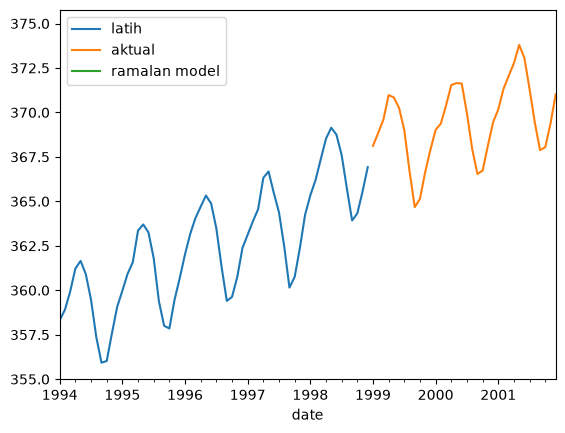

In [7]:
predictions = forecast(train, HORIZON)
naive = np.resize(train.iloc[-SEASON_LENGTH:].to_numpy(), HORIZON)   # ulang musim terakhir
print("Model       MAE:", round(mean_absolute_error(test, predictions), 2),
      "| RMSE:", round(root_mean_squared_error(test, predictions), 2),
      "| MAPE(%):", round(100 * mean_absolute_percentage_error(test, predictions), 2))
print("Naive musim MAE:", round(mean_absolute_error(test, naive), 2),
      "| RMSE:", round(root_mean_squared_error(test, naive), 2),
      "| MAPE(%):", round(100 * mean_absolute_percentage_error(test, naive), 2))

ax = train.iloc[-5 * SEASON_LENGTH:].plot(label="latih")
test.plot(ax=ax, label="aktual")
ax.plot(test.index, predictions, label="ramalan model")
ax.legend()
plt.show()

## Latih ulang di semua data + hasil ramalan ke depan

In [8]:
future_values = forecast(y, HORIZON)
future_dates = pd.date_range(start=y.index[-1], periods=HORIZON + 1, freq=FREQUENCY)[1:]

result = pd.DataFrame()
result["tanggal"] = future_dates
result["ramalan"] = future_values
result.to_csv("hasil.csv", index=False)
result.head()

,tanggal,ramalan
0,2002-01-01,371.895613
1,2002-02-01,372.644980
2,2002-03-01,373.512248
3,2002-04-01,374.686412
4,2002-05-01,375.159514
